# **Prophet vs XGboost: Inflação central**

**Introdução do projeto**

Importação das bibliotecas pandas
criação de um dicionário com o código de cada um dos bancos de dados selecionados:
 * IPCA — Índice de Preços ao Consumidor Amplo (índice oficial de inflação do Brasil, calculado pelo IBGE)
 * SELIC — Sistema Especial de Liquidação e Custódia (taxa básica de juros da economia brasileira, definida pelo Banco Central a cada 45 dias pelo COPOM)
 * Câmbio — Taxa USD/BRL (quantos reais valem um dólar americano)
 * IGP-M — Índice Geral de Preços do Mercado (mede a variação de preços no atacado, na construção civil e no varejo, Tende a antecipar movimentos do IPCA, o que sobe no atacado hoje chega ao consumidor final depois.)

 após isso aplicamos uma estrutura de repetição para buscar o banco de dados por meio da API e seu código, a API do BCB rejeita requisições sem identificação de navegador. Nesse sentido, utilizamos um header para nos idenfticar e enviar um request para obtermos uma response(resposta), após isso lemos essa resposta em json e em seguida passamos para a forma de dataframe. Após isso, deixamos a coluna de data no formate datetime e caso as colunas de valores tenha algum erro, retorna um valor nulo no lugar ao invés do código simplesmente quebrar, renomeio cada coluna com seu nome e printo a quantidade de registros e o range da data


In [1]:

import pandas as pd
import requests

codigos = {
    'ipca': 433,
    'selic': 4189,
    'cambio': 3698,
    'igpm': 189
}

dfs = {}
for nome, codigo in codigos.items():
    url = f'https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json'
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    df_temp = pd.DataFrame(response.json())
    df_temp['data'] = pd.to_datetime(df_temp['data'], format='%d/%m/%Y')
    df_temp['valor'] = pd.to_numeric(df_temp['valor'], errors='coerce')
    df_temp = df_temp.rename(columns={'valor': nome})
    dfs[nome] = df_temp

print("Séries carregadas:")
for nome, df in dfs.items():
    print(f"{nome}: {df.shape[0]} registros | {df['data'].min().date()} até {df['data'].max().date()}")

Séries carregadas:
ipca: 557 registros | 1980-01-01 até 2026-05-01
selic: 479 registros | 1986-08-01 até 2026-06-01
cambio: 880 registros | 1953-02-01 até 2026-05-01
igpm: 444 registros | 1989-06-01 até 2026-05-01


In [2]:
for nome, df in dfs.items():
    print(f"\n{nome}:")
    print(df.tail())


ipca:
          data  ipca
552 2026-01-01  0.33
553 2026-02-01  0.70
554 2026-03-01  0.88
555 2026-04-01  0.67
556 2026-05-01  0.58

selic:
          data  selic
474 2026-02-01  14.90
475 2026-03-01  14.80
476 2026-04-01  14.64
477 2026-05-01  14.40
478 2026-06-01  14.38

cambio:
          data  cambio
875 2026-01-01  5.3380
876 2026-02-01  5.2006
877 2026-03-01  5.2316
878 2026-04-01  5.0331
879 2026-05-01  4.9837

igpm:
          data  igpm
439 2026-01-01  0.41
440 2026-02-01 -0.73
441 2026-03-01  0.52
442 2026-04-01  2.73
443 2026-05-01  0.84


Fazemos uma cópia necessária para garantir que o DataFrame original do dicionário dfs não seja alterado durante as transformações subsequentes. Nesse sentido, passamos esta cópia para dentro da variável df_master, após isso fazemos que para cada coluna cujos nomes estão na seleção, seja feito um merge tendo a coluna data como referência utilizando o método inner. Diante disso, temos um dataframe único com os valores cconectados pelas mesmas datas. 
Obs: The exchange rate series (code 3694) was identified as annual frequency and replaced by the monthly series (code 3698) prior to merging

In [ ]:
df_master = dfs['ipca'].copy()

for nome in ['selic', 'cambio', 'igpm']:
    df_master = df_master.merge(dfs[nome], on='data', how='inner')

print(df_master.shape)
print(df_master.head())
print(df_master.tail())


(444, 5)
        data   ipca     selic  cambio   igpm
0 1989-06-01  28.65   1486.02   1.337  19.68
1 1989-07-01  27.74   3005.24   1.914  35.90
2 1989-08-01  33.71   2687.61   2.475  36.92
3 1989-09-01  37.56   6002.01   3.267  39.92
4 1989-10-01  39.77  10676.54   4.490  40.64
          data  ipca  selic  cambio  igpm
439 2026-01-01  0.33  14.90  5.3380  0.41
440 2026-02-01  0.70  14.90  5.2006 -0.73
441 2026-03-01  0.88  14.80  5.2316  0.52
442 2026-04-01  0.67  14.64  5.0331  2.73
443 2026-05-01  0.58  14.40  4.9837  0.84


# **EDA**

O dataset foi filtrado a partir de janeiro de 2000. O período de hiperinflação anterior ao Plano Real (1994) produziu variações de magnitude completamente diferente do regime monetário atual. Incluir dados anteriores a 2000 introduziria padrões incompatíveis com a dinâmica inflacionária atual, comprometendo a generalização dos modelos. Ademais, o reset_index(drop=True) é aplicado após o filtro para que os índices sejam reiniciados a partir de zero. Sem isso, os índices do DataFrame filtrado manteriam a numeração original, por exemplo, começando em 132 em vez de 0, o que pode causar problemas em operações subsequentes que assumem índices sequenciais.

In [5]:


df_master = df_master[df_master['data'] >= '2000-01-01'].reset_index(drop=True)
df_master.head()


,data,ipca,selic,cambio,igpm
0,2000-01-01,0.62,18.94,1.8037,1.24
1,2000-02-01,0.13,18.87,1.7753,0.35
2,2000-03-01,0.22,18.85,1.7420,0.15
3,2000-04-01,0.42,18.62,1.7682,0.23
4,2000-05-01,0.01,18.51,1.8279,0.31


In [6]:
# Plotting

import plotly.express as px
def plotting(title, data, x, y, x_label, y_label ):
    fig = px.line(data, x=df_master[x], y=df_master[y], labels={x: x_label, y: y_label})

    fig.update_layout(template='simple_white', font=dict(size=18), title_text = title, width=650, title_x = 0.5, height = 400)

    fig.show()

plotting('Evolução do IPCA (2000-2025)', df_master, 'data', 'ipca', 'Date', 'Values')






<Figure size 1000x500 with 0 Axes>

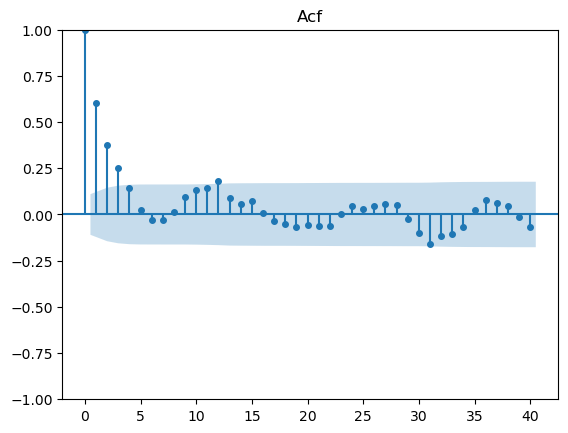

In [7]:
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
ipca = df_master['ipca']
plt.figure(figsize=(10, 5))
plot_acf(ipca, lags=40, markersize=4)
plt.title('Acf')
plt.show()

In [8]:
print(ipca.describe())
print(f"Valores negativos: {(ipca < 0).sum()}")
print(f"Valores zero: {(ipca == 0).sum()}")

count    317.000000
mean       0.497445
std        0.391810
min       -0.680000
25%        0.260000
50%        0.450000
75%        0.670000
max        3.020000
Name: ipca, dtype: float64
Valores negativos: 15
Valores zero: 1


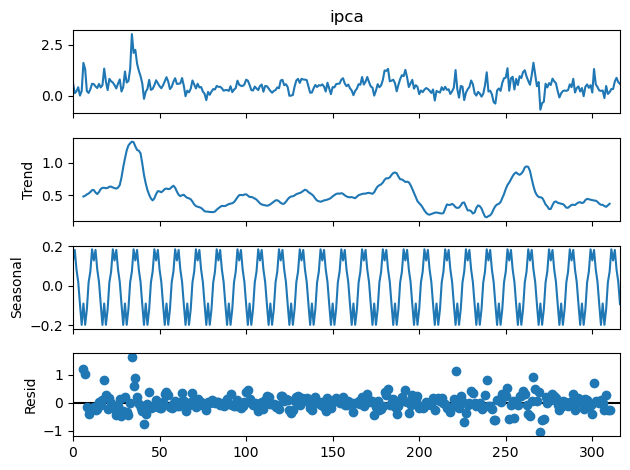

In [9]:
from statsmodels.tsa.seasonal import seasonal_decompose

decompose = seasonal_decompose(ipca, model='additive', period=12)
decompose.plot()
plt.show()


As we can see, a tendência não possui uma direção fixa pois como sabemos as taxa da inflação oscila constantemente. Ademais, na parte de sazonalidade podemos ver que em periodos sazonais há um aumento ou um redução de 0.2 pontos percentuais. Nos resiudos conseguimos ver que eles seguem uma distribuição na linha 0, o que nesse caso faz sentido ja que estamos utilizando o método aditivo cujo elemento neutro é o 0.

## Analisando sua distribuição

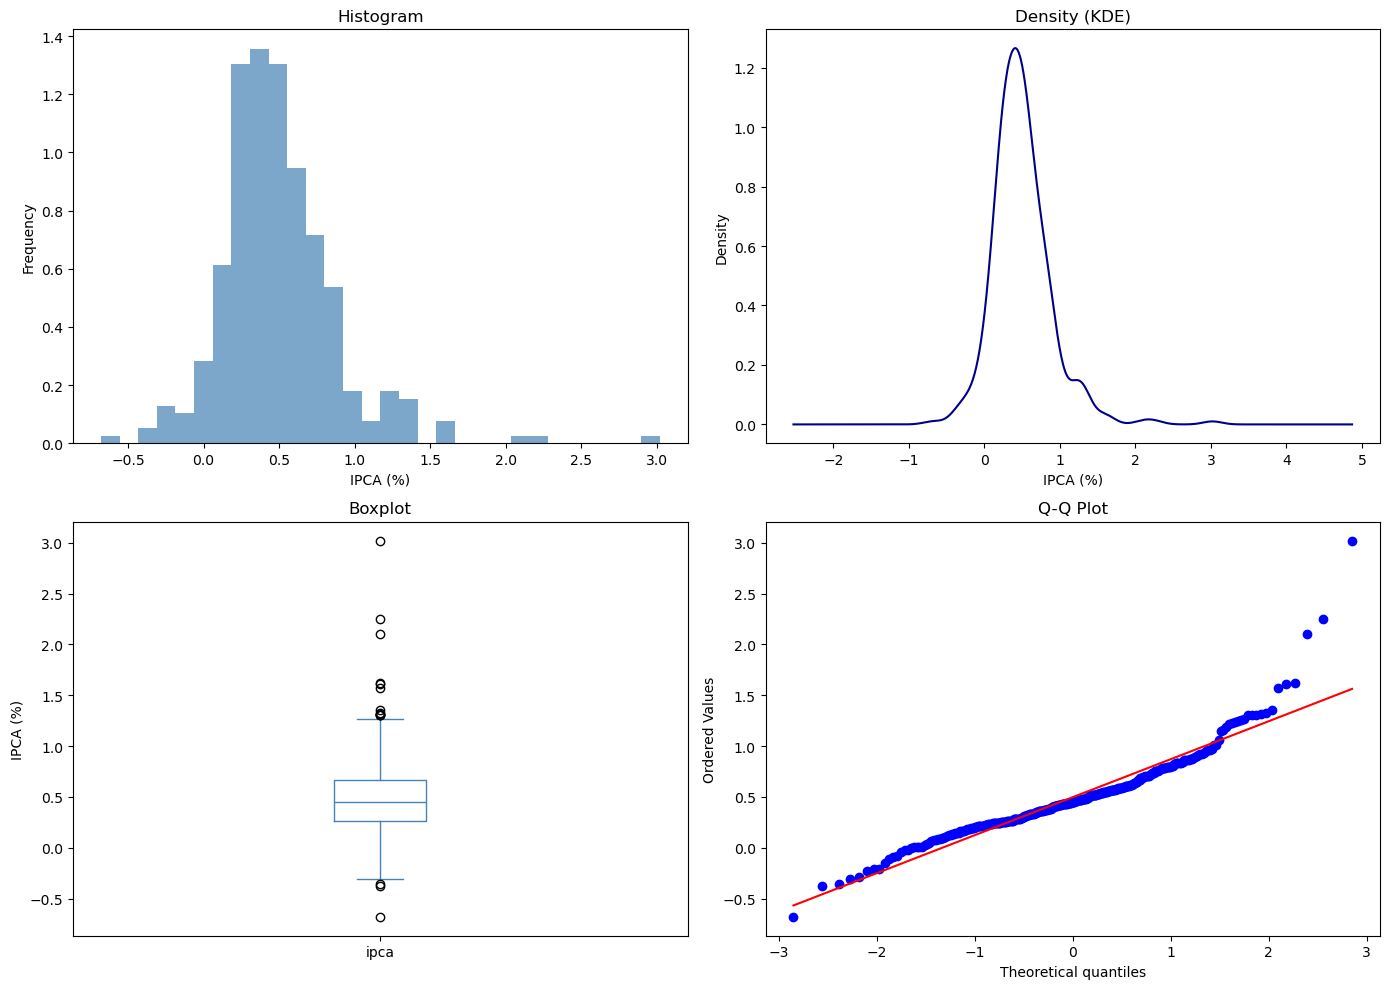

In [10]:
import scipy.stats as stats

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histograma
ipca.plot(kind='hist', bins=30, density=True, ax=axes[0, 0], color='steelblue', alpha=0.7)
axes[0, 0].set_title('Histogram')
axes[0, 0].set_xlabel('IPCA (%)')

# KDE
ipca.plot(kind='kde', ax=axes[0, 1], color='darkblue')
axes[0, 1].set_title('Density (KDE)')
axes[0, 1].set_xlabel('IPCA (%)')

# Boxplot
ipca.plot(kind='box', ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Boxplot')
axes[1, 0].set_ylabel('IPCA (%)')

# Q-Q Plot
stats.probplot(ipca, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

No histograma e kde é possível perceber que a distribuição assume uma assimetria positiva, tendo uma cauda maior a direita. o que faz sentido já que no sentido  de deflações é normal que tenham um limite natural perto de zero, porém as inflações ja não possuem esse limite especifico e podem subir dependendo do estado economico em que se encontra o país. Ademais, nos gráficos de boxplot e Q-Q plot notamos alguns outliers que se conferirmos na base da SGS bcb, correspondem ao 3 meses seguidos do ano de 2002(Novembro/Dezembro)/2003(Janeiro) tendo o contexto da crise cambial brasileira de 2002 que foi marcada pela desconfiança do mercado financeiro em relação à possível vitória de Luiz Inácio Lula da Silva nas eleições presidenciais, gerando ataques especulativos contra o real. O cenário foi caracterizado por uma disparada do dólar

##  ADF - KPSS

In [11]:
from statsmodels.tsa.stattools import adfuller, kpss

def adf(x):
    result = adfuller(x)
    print(f'ADF TESTE: ')
    print(f'Statistic: {result[0]}')
    print(f'P-value: {result[1]:.15f}')
    for key, value in result[4].items():
        print(F'{key}: {value:.3f}')

adf(ipca)
print('\n')
def kps(x):
    result = kpss(ipca, regression='c', nlags='auto')
    print(f'KPSS TESTE: ')
    print(f'Statistic: {result[0]:.3f}')
    print(f'P-value: {result[1]}')
    for key, value in result[3].items():
        print(F'{key}: {value:.3f}')

kps(ipca)



ADF TESTE: 
Statistic: -8.812512609303813
P-value: 0.000000000000020
1%: -3.451
5%: -2.871
10%: -2.572


KPSS TESTE: 
Statistic: 0.250
P-value: 0.1
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739


C:\Users\mmmar\AppData\Local\Temp\ipykernel_19556\856084073.py:14: InterpolationWarning:

The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.




ADF — estatística de -8.75, mais negativa que o valor crítico de 1%, e p-value abaixo de 0.05. Rejeita H0. A série não tem raiz unitária.

KPSS — estatística de 0.259, menor que o valor crítico de 10%. P-value de 0.1. não rejeita H0. A série é estacionária segundo o KPSS também.

A conclusão é que o IPCA pós-2000 não precisa de diferenciação antes de modelar.

## ACF

C:\Users\mmmar\AppData\Local\Temp\ipykernel_19556\818052998.py:6: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



<Figure size 1000x400 with 0 Axes>

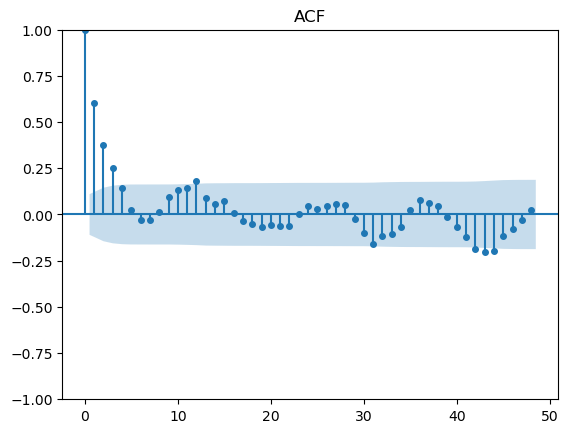

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig = plt.figure(figsize=(10, 4))
auto = plot_acf(ipca, lags=48, markersize=4)
plt.title('ACF')
fig.show()

Lag 0 sempre é 1 — autocorrelação perfeita consigo mesmo, ignorar
Lag 1 significativo (~0.6) — o IPCA deste mês está correlacionado com o do mês anterior
Lags 2 e 3 ainda significativos mas decaindo rapidamente
A partir do lag 4 a maioria entra na área azul — sem correlação relevante
Não há picos nos lags 12, 24, 36 — confirma que a sazonalidade anual é fraca no IPCA pós-2000.

## PACF

C:\Users\mmmar\AppData\Local\Temp\ipykernel_19556\2631409769.py:4: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



<Figure size 1000x400 with 0 Axes>

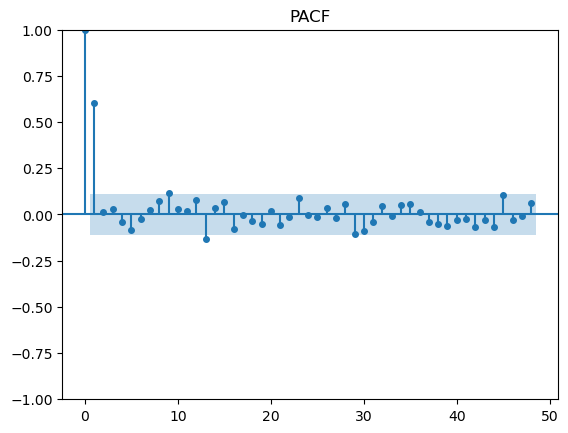

In [13]:

fig = plt.figure(figsize=(10, 4))
auto = plot_pacf(ipca, lags=48, markersize=4)
plt.title('PACF')
fig.show()

Lag 1 significativo (~0.6) — correlação direta forte com o mês anterior
Lag 2 ainda fora da área azul mas bem menor
A partir do lag 3 praticamente tudo dentro da área azul — corte abrupto

A estrutura é de um processo AR de ordem baixa, o IPCA de hoje é influenciado principalmente pelo IPCA do mês anterior. Isso justifica o uso de ipca_lag1 como feature principal no XGBoost.
O ipca_lag12 que planejamos usar é mais uma decisão de domínio do que estatística. Sazonalidade anual faz sentido economicamente (reajustes anuais de energia, planos de saúde) mesmo não aparecendo forte no ACF.

vamos usar o lag 12 no XGBoost mesmo sem aparecer forte no ACF porque economicamente faz sentido, contratos de aluguel, planos de saúde e energia elétrica são reajustados anualmente. Então o IPCA de janeiro de 2024 tem alguma relação com o de janeiro de 2023. 